# Классификация облаков
## Цель:
  1. построить модель классификации облачных структур по спутниковым изображениям;
  2. проанализировать результаты классификации для исследования особенностей организации облаков.


In [1]:
# Скачиваю архив с Google Drive по id файла из ссылки задания
!gdown 1leoj71B_D_paBLC1uP5EKcnR5lJFPovn -O clouds.zip

# Распаковываю в папку data
!unzip -q clouds.zip -d data

!find data -maxdepth 2 -not -name "*.jpg"

Downloading...
From (original): https://drive.google.com/uc?id=1leoj71B_D_paBLC1uP5EKcnR5lJFPovn
From (redirected): https://drive.google.com/uc?id=1leoj71B_D_paBLC1uP5EKcnR5lJFPovn&confirm=t&uuid=0445a6ef-af82-4c01-b493-f3444ea5b533
To: /content/clouds.zip
100% 6.23G/6.23G [01:40<00:00, 62.1MB/s]
data
data/test_images
data/train.csv
data/sample_submission.csv
data/train_images


In [2]:
import torch

print("GPU доступна:", torch.cuda.is_available())
print("Модель GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "нет")

GPU доступна: True
Модель GPU: Tesla T4


In [3]:
import matplotlib.pyplot as plt
from PIL import Image
import seaborn as sns
import numpy as np
import torch.nn.functional as F
import pandas as pd
import os
from tqdm.auto import tqdm
import torchvision.transforms as T
import torchvision.models as models
from torch.utils.data import Dataset, DataLoader
import torch.nn as nn
import time

Фиксирую случайность, чтобы при перезапуске блокнота результаты обучения повторялись.

In [4]:
import random

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)

In [5]:
df = pd.read_csv("data/train.csv")
print(df.shape)
df.head(8)

(22184, 2)


,Image_Label,EncodedPixels
0,0011165.jpg_Fish,264918 937 266318 937 267718 937 269118 937 27...
1,0011165.jpg_Flower,1355565 1002 1356965 1002 1358365 1002 1359765...
2,0011165.jpg_Gravel,NaN
3,0011165.jpg_Sugar,NaN
4,002be4f.jpg_Fish,233813 878 235213 878 236613 878 238010 881 23...
5,002be4f.jpg_Flower,1339279 519 1340679 519 1342079 519 1343479 51...
6,002be4f.jpg_Gravel,NaN
7,002be4f.jpg_Sugar,67495 350 68895 350 70295 350 71695 350 73095 ...


В таблице 22 184 строки и 2 столбца. На каждый снимок приходится 4 строки (по одной на тип облаков), значит снимков 22 184 / 4 = 5 546
Nan - этого типа на снимке нет

In [6]:
#Переделаю в удобный вид. Одна строка = один снимок, 4 столбца с 0 или 1

# "0011165.jpg_Fish". Делю по "_" на два столбца (имя снимка и класс)
df[["image", "label"]] = df["Image_Label"].str.split("_", expand=True)

# notna(). True/False в 1/0
df["has"] = df["EncodedPixels"].notna().astype(int)

# Разворачиваю строки — снимки, столбцы — классы, в ячейках — 0/1 + фиксирую столбцы
labels = df.pivot(index="image", columns="label", values="has")
labels = labels[["Sugar", "Gravel", "Fish", "Flower"]]

labels.head()

label,Sugar,Gravel,Fish,Flower
image,,,,
0011165.jpg,0,0,1,1
002be4f.jpg,1,0,1,1
0031ae9.jpg,1,0,1,1
0035239.jpg,0,1,0,1
003994e.jpg,1,1,1,0


In [7]:
#Всего снимков
len(labels)

5546

In [8]:
#На скольких снимках встречается каждый тип
labels.sum()

,0
label,
Sugar,3751
Gravel,2939
Fish,2781
Flower,2365


Sugar самый частый узор, Flower самый редкий, классы сбалансированы.


In [9]:
#Сколько типов облаков бывает на одном снимке
labels.sum(axis=1).value_counts().sort_index()

,count
1,1348
2,2372
3,1560
4,266


Большая часть снимков (4198 из 5546) содержит 2 и больше типов облаков. Задача многометочная, модель не должна выбирать один из четырех типов, ей нужно отдельно ответить про каждый тип. Снимков без облаков нет, на каждом хотя бы один тип.

Делаю сетку 2х3 из картинок, беру первые 6 снимков и определяю каждый в свою клетку сетки, собираю список классов 1

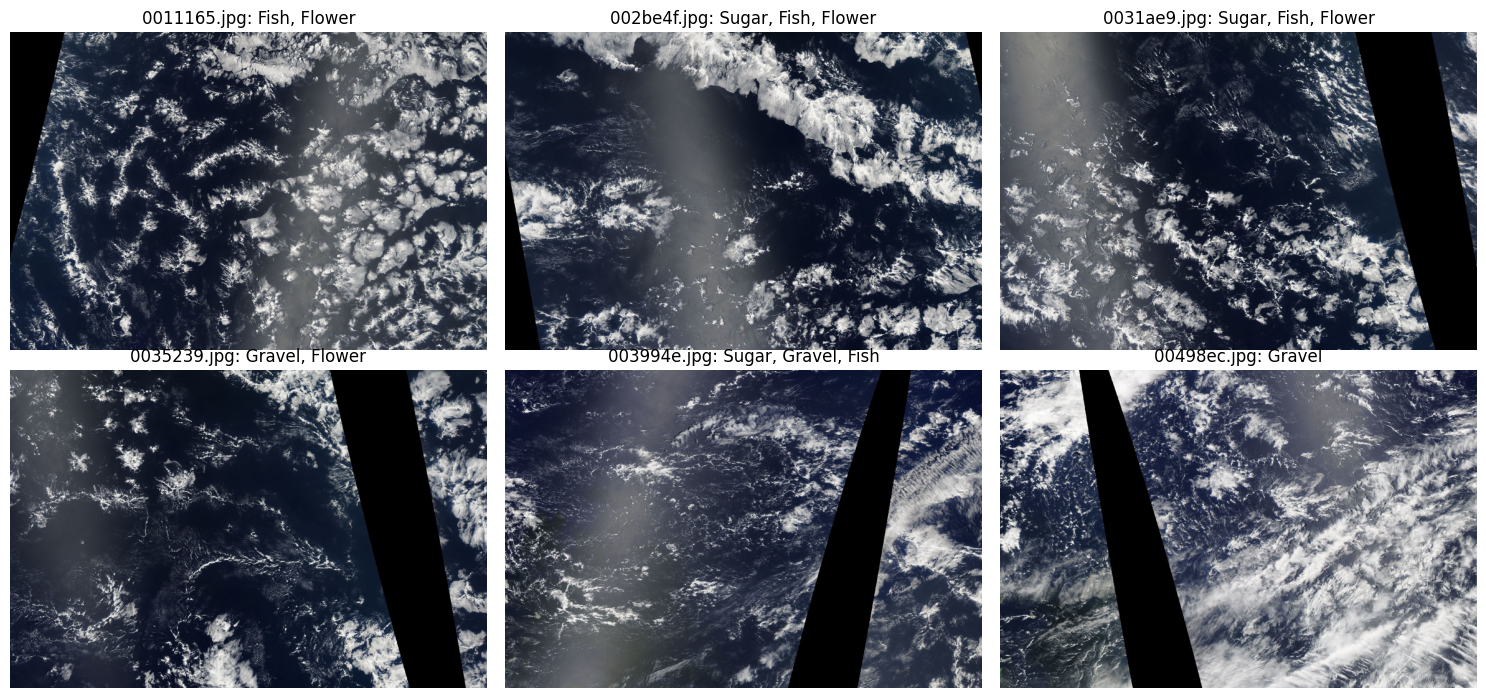

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7))

for ax, name in zip(axes.flat, labels.index[:6]):
    img = Image.open(f"data/train_images/{name}")
    ax.imshow(img)

    present = [c for c in labels.columns if labels.loc[name, c] == 1]
    ax.set_title(f"{name}: {', '.join(present)}")
    ax.axis("off")

plt.tight_layout()
plt.show()

На снимках:
- Есть помехи (черные полосы и солнечные блики);
- Различить Sugar и Gravel трудно, модель может путать эти классы.

## Какие облака встречаются вместе
- labels.T — транспонирую таблицу;
- @ матричное умножение;
- Heatmap. Тепловая карта, цвет клетки показывает величину числа.


label   Sugar  Gravel  Fish  Flower
label                              
Sugar    3751    2067  1782    1405
Gravel   2067    2939  1423     926
Fish     1782    1423  2781    1045
Flower   1405     926  1045    2365


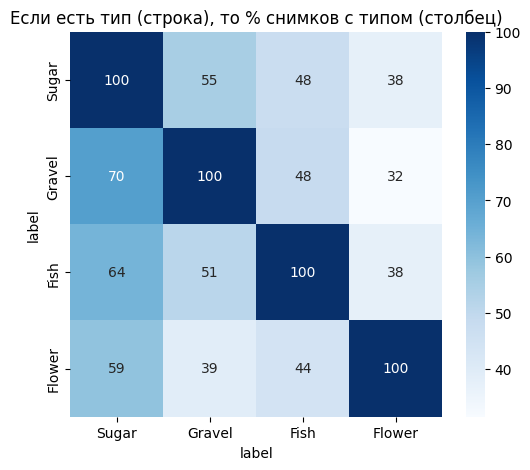

In [11]:
co = labels.T @ labels
print(co)

co_pct = (co.div(co.values.diagonal(), axis=0) * 100).round(1)

plt.figure(figsize=(6, 5))
sns.heatmap(co_pct, annot=True, fmt=".0f", cmap="Blues")
plt.title("Если есть тип (строка), то % снимков с типом (столбец)")
plt.show()

1. Sugar и Gravel чаще всего встречаются вместе (2 067 снимков), но в основном просто потому, что оба частые;
2. Flower и Gravel редко бывают на одном снимке;
3. Связи между классами умеренные, ни одна пара не встречается всегда вместе.


## Обучение нейросети, градиентный спуск на примере
Подбираю w и b для зависимости y = 2x + 1 с разной скоростью обучения (lr).
1. Модель делает предсказание
2. Считает ошибку
3. backpropagation - подсчет градиентов
4. no_grad - шаг не нужно отслеживать
5. обнуление градиентов (новые на каждом шаге)

In [12]:
# С шагом 0.01
x = torch.tensor([1., 2., 3., 4.])
y = torch.tensor([3., 5., 7., 9.])

w = torch.tensor(0.0, requires_grad=True)
b = torch.tensor(0.0, requires_grad=True)

lr = 0.01

for step in range(1001):
    pred = w * x + b
    loss = ((pred - y) ** 2).mean()
    loss.backward()

    with torch.no_grad():
        w -= lr * w.grad
        b -= lr * b.grad
        w.grad.zero_()
        b.grad.zero_()

    if step % 200 == 0:
        print(f"шаг {step:4d}, ошибка {loss.item():.4f}, w = {w.item():.3f}, b = {b.item():.3f}")

шаг    0, ошибка 41.0000, w = 0.350, b = 0.120
шаг  200, ошибка 0.0041, w = 2.053, b = 0.843
шаг  400, ошибка 0.0012, w = 2.029, b = 0.914
шаг  600, ошибка 0.0004, w = 2.016, b = 0.953
шаг  800, ошибка 0.0001, w = 2.009, b = 0.974
шаг 1000, ошибка 0.0000, w = 2.005, b = 0.986


In [13]:
# С шагом 0.02
x = torch.tensor([1., 2., 3., 4.])
y = torch.tensor([3., 5., 7., 9.])

w = torch.tensor(0.0, requires_grad=True)
b = torch.tensor(0.0, requires_grad=True)

lr = 0.02

for step in range(1001):
    pred = w * x + b
    loss = ((pred - y) ** 2).mean()
    loss.backward()

    with torch.no_grad():
        w -= lr * w.grad
        b -= lr * b.grad
        w.grad.zero_()
        b.grad.zero_()

    if step % 200 == 0:
        print(f"шаг {step:4d}, ошибка {loss.item():.4f}, w = {w.item():.3f}, b = {b.item():.3f}")

шаг    0, ошибка 41.0000, w = 0.700, b = 0.240
шаг  200, ошибка 0.0012, w = 2.029, b = 0.914
шаг  400, ошибка 0.0001, w = 2.009, b = 0.974
шаг  600, ошибка 0.0000, w = 2.003, b = 0.992
шаг  800, ошибка 0.0000, w = 2.001, b = 0.998
шаг 1000, ошибка 0.0000, w = 2.000, b = 0.999


In [14]:
# С шагом 0.2
x = torch.tensor([1., 2., 3., 4.])
y = torch.tensor([3., 5., 7., 9.])

w = torch.tensor(0.0, requires_grad=True)
b = torch.tensor(0.0, requires_grad=True)

lr = 0.2

for step in range(1001):
    pred = w * x + b
    loss = ((pred - y) ** 2).mean()
    loss.backward()

    with torch.no_grad():
        w -= lr * w.grad
        b -= lr * b.grad
        w.grad.zero_()
        b.grad.zero_()

    if step % 200 == 0:
        print(f"шаг {step:4d}, ошибка {loss.item():.4f}, w = {w.item():.3f}, b = {b.item():.3f}")

шаг    0, ошибка 41.0000, w = 7.000, b = 2.400
шаг  200, ошибка nan, w = nan, b = nan
шаг  400, ошибка nan, w = nan, b = nan
шаг  600, ошибка nan, w = nan, b = nan
шаг  800, ошибка nan, w = nan, b = nan
шаг 1000, ошибка nan, w = nan, b = nan


При lr = 0.01 и 0.02 модель сама нашла w ~ 2 и b ~ 1, при 0.02 быстрее. При lr = 0.2 шаги слишком большие, модель перескакивает минимум, ошибка растет до бесконечности (nan). Это взрыв градиента, поэтому скорость обучения нужно подбирать.

## Свертка
1. Открываю снимок и делаю его черно-белым ("L"), чтобы был 1 канал;
2. Перевожу в тензор формы [1, 1, H, W] и делю на 255, чтобы числа были 0 1;

[1, 1, H, W] для картинок [сколько картинок, сколько каналов, высота, ширина]. [None, None] добавляет две недостающие размерности спереди.

3. Фильтр вертикальных границ перевожу в формы [1, 1, 3, 3];
4. out = F.conv2d(x, kernel) - свертка
5. abs() берет модуль числа, чтобы были видны и переходы темное-светлое.

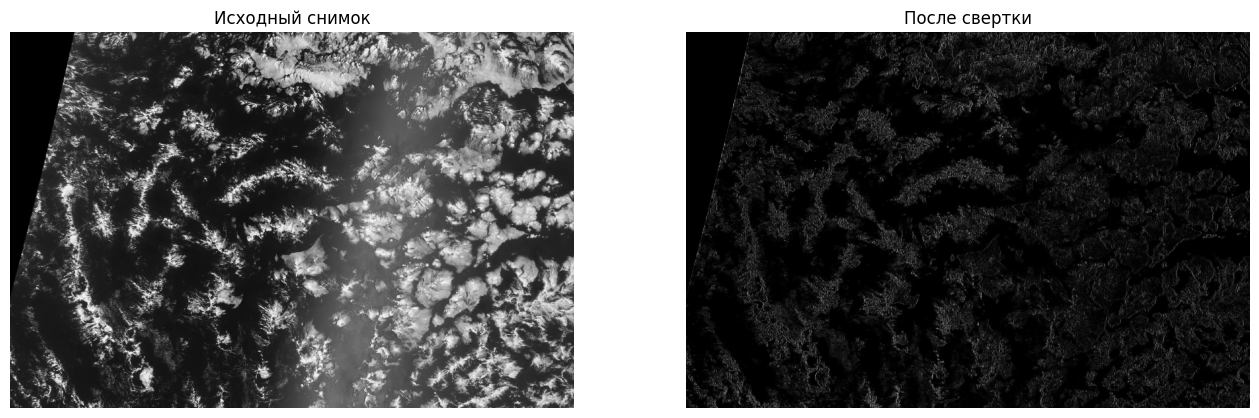

In [15]:
img = Image.open("data/train_images/0011165.jpg").convert("L")

x = torch.tensor(np.array(img), dtype=torch.float32)[None, None] / 255

kernel = torch.tensor([[-1., 0, 1],
                       [-1., 0, 1],
                       [-1., 0, 1]])[None, None]

out = F.conv2d(x, kernel)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
axes[0].imshow(x[0, 0], cmap="gray"); axes[0].set_title("Исходный снимок")
axes[1].imshow(out[0, 0].abs(), cmap="gray"); axes[1].set_title("После свертки")
for ax in axes: ax.axis("off")
plt.show()

## Данные для обучения
Оставляю 20% на валидацию

In [16]:
from sklearn.model_selection import train_test_split

train_names, val_names = train_test_split(
    labels.index.tolist(), test_size=0.2, random_state=42
)

print("Обучение:", len(train_names))
print("Валидация:", len(val_names))

Обучение: 4436
Валидация: 1110


In [17]:
# Уменьшаю снимки
os.makedirs("data/train_small", exist_ok=True)

for name in tqdm(labels.index):
    img = Image.open(f"data/train_images/{name}")
    img = img.resize((480, 320))
    img.save(f"data/train_small/{name}")

  0%|          | 0/5546 [00:00<?, ?it/s]

## Аугментация
1. Только на train;
2. T.RandomHorizontalFlip() - с вероятностью 50% отразить слева направо;
3. T.RandomVerticalFlip() - с вероятностью 50% отразить сверху вниз;
4. T.ToTensor() - картинка - тензор [3, H, W], числа 0 1

In [18]:
train_tf = T.Compose([
    T.RandomHorizontalFlip(),
    T.RandomVerticalFlip(),
    T.ToTensor(),
    T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

val_tf = T.Compose([
    T.ToTensor(),
    T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

## Dataset и DataLoader
1. __len__ - сколько всего снимков
2. __getitem__ - получить снимок номер i и его ответ
3. self.names = names - список имен снимков
4. self.labels = labels - таблица ответов 0/1
5. self.folder = folder - папка со снимками
6. self.transform = transform - что делать с картинкой


In [19]:
CLASSES = ["Sugar", "Gravel", "Fish", "Flower"]

class CloudDataset(Dataset):
    def __init__(self, names, labels, folder, transform):
        self.names = names
        self.labels = labels
        self.folder = folder
        self.transform = transform

    def __len__(self):
        return len(self.names)

    def __getitem__(self, i):
        name = self.names[i]
        img = Image.open(f"{self.folder}/{name}").convert("RGB")
        x = self.transform(img)
        y = torch.tensor(self.labels.loc[name, CLASSES].values,
                         dtype=torch.float32)
        return x, y

shuffle=True - перемешивать снимки каждый раз, чтобы сеть не привыкла к порядку

In [20]:
train_ds = CloudDataset(train_names, labels, "data/train_small", train_tf)
val_ds   = CloudDataset(val_names, labels, "data/train_small", val_tf)

train_dl = DataLoader(train_ds, batch_size=16, shuffle=True, num_workers=2,
                      generator=torch.Generator().manual_seed(42))
val_dl = DataLoader(val_ds,   batch_size=16, shuffle=False, num_workers=2)

x, y = next(iter(train_dl))
print("Снимки:", x.shape)
print("Ответы:", y.shape)
print(y[:4])

Снимки: torch.Size([16, 3, 320, 480])
Ответы: torch.Size([16, 4])
tensor([[1., 1., 1., 1.],
        [0., 0., 0., 1.],
        [0., 0., 0., 1.],
        [1., 1., 1., 0.]])


## Собираю сверточную сеть
Свертка-BatchNorm- ReLU-уменьшение в 2 раза

1. Sequential - выполнить по очереди;
2. c_out - фильтры 3х3;
3. BatchNorm - нормализация;
4. ReLU - отрицательные значения заменяются нулями;
5. MaxPool2d(2) - из каждого квадрата 2х2 беру максимум.



In [21]:
def conv_block(c_in, c_out):
    return nn.Sequential(
        nn.Conv2d(c_in, c_out, kernel_size=3, padding=1),
        nn.BatchNorm2d(c_out),
        nn.ReLU(),
        nn.MaxPool2d(2),
    )

1. nn.Module - основа сети в PyTorch;
2. self.pool = nn.AdaptiveAvgPool2d(1) - каждая из 256 карт сжимается в одно число (ее среднее значение) для поиска, сколько этого признака на всем снимке;
3. nn.Flatten() - [16, 256, 1, 1] -> [16, 256] убираю лишние размерности;
4. nn.Dropout(0.3) - при обучении убираем 30% признаков;
5. nn.Linear(256, 4) - 256 признаков, 4 ответа.
        

In [22]:
class SimpleCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            conv_block(3, 32),
            conv_block(32, 64),
            conv_block(64, 128),
            conv_block(128, 256),
            conv_block(256, 256),
        )

        self.pool = nn.AdaptiveAvgPool2d(1)

        self.head = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.3),
            nn.Linear(256, 4),
        )

    def forward(self, x):
        x = self.features(x)
        x = self.pool(x)
        return self.head(x)

## Проверка
1. device = "cuda" - считаю на видеокарте;
2. model = SimpleCNN().to(device) - создаю сеть и переношу ее на GPU


In [23]:
device = "cuda"
model = SimpleCNN().to(device)

out = model(x.to(device))
print("Выход:", out.shape)
print(out[:2])

n_params = sum(p.numel() for p in model.parameters())
print(f"Параметров: {n_params:,}")

Выход: torch.Size([16, 4])
tensor([[ 0.8471,  0.2148, -1.1890,  0.4285],
        [ 0.2464, -0.2167, -0.5905,  0.8473]], device='cuda:0',
       grad_fn=<SliceBackward0>)
Параметров: 980,996


На выходе [16, 4] (16 снимков и 4 типа облаков), параметров 980 996.

## Обучение
## Функция Dice

Проверяю, какой Dice получит самая простая модель, которая не смотрит на снимок и на каждый отвечает "есть все 4 типа облаков". Этот результат станет точкой отсчета. Нейросеть должна получить Dice выше, иначе от нее нет пользы.

1. pred и true тензоры [N, 4] из 0 и 1. Возвращает Dice для каждого из 4 классов;
2. sum(dim=0) - суммирую по всем снимкам отдельно для каждого класса.
3. eps - маленькое число, чтобы не делить на 0, если класс нигде не встретился.


In [24]:
def dice_score(pred, true, eps=1e-7):
    inter = (pred * true).sum(dim=0)
    total = pred.sum(dim=0) + true.sum(dim=0)
    return (2 * inter + eps) / (total + eps)

In [25]:
val_true = torch.tensor(labels.loc[val_names, CLASSES].values, dtype=torch.float32)

always_yes = torch.ones_like(val_true)

d = dice_score(always_yes, val_true)
for c, v in zip(CLASSES, d):
    print(f"{c:7s} {v:.3f}")
print(f"Средний Dice: {d.mean():.3f}")

Sugar   0.812
Gravel  0.701
Fish    0.681
Flower  0.594
Средний Dice: 0.697


Итог: Dice нейросети должен быть больше 0.70, иначе она не лучше модели-заглушки.

## train_one_epoch
Функция одной эпохи обучения. сеть по очереди просматривает все обучающие снимки пачками по 16 и после каждой пачки немного корректирует свои параметры. Чтобы не было взрыва градиента, слишком большие градиенты обрезаются.

1. x, y = x.to(device), y.to(device) - перенос на видеокарту;
2. logits = model(x) - предсказание;
3. loss = loss_fn(logits, y) - ошибка;
4. optimizer.zero_grad() - обнуление старых градиентов;
5. loss.backward() - backpropagation;
6. torch.nn.utils.clip_grad_norm_ - обрезка слишком больших градиентов;
7. optimizer.step() - шаг Adam;
8. total_loss - средняя ошибка за эпоху.

In [26]:
def train_one_epoch(model, loader, optimizer, loss_fn):
    model.train()
    total_loss = 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)

        logits = model(x)
        loss = loss_fn(logits, y)

        optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()

        total_loss += loss.item() * len(x)
    return total_loss / len(loader.dataset)

## evaluate
Функция проверки. Сеть отвечает на валидационные снимки, которые не видела при обучении, считаю ее ошибку и Dice. Параметры сети здесь не меняются.
1. model.eval() - режим проверки, Dropout выключен;
2. logits - сырые числа сети, в вероятности от 0 до 1 их превращает sigmoid;
3. probs > 0.5, true - порог 0.5, вероятность 0/1.

In [27]:
@torch.no_grad()
def evaluate(model, loader, loss_fn):
    model.eval()
    total_loss = 0
    all_probs, all_true = [], []
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        logits = model(x)
        total_loss += loss_fn(logits, y).item() * len(x)
        all_probs.append(torch.sigmoid(logits).cpu())
        all_true.append(y.cpu())

    probs = torch.cat(all_probs)
    true = torch.cat(all_true)
    dice = dice_score((probs > 0.5).float(), true)
    return total_loss / len(loader.dataset), dice, probs, true

## Цикл обучения
Обучаю сеть 15 эпох и после каждой проверяю ее на валидации. Лучшую версию по Dice сохраняю, чтобы не потерять ее, если сеть начнет переобучаться.

1. model = SimpleCNN().to(device) - создаю сеть заново;
2. history = [] - запись процесса обучения;
3. mark - лучшая версия сети по Dice на валидации.

In [28]:
set_seed(42)
model = SimpleCNN().to(device)
loss_fn = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

EPOCHS = 15
history = []
best_dice = 0

for epoch in range(1, EPOCHS + 1):
    t0 = time.time()
    tr_loss = train_one_epoch(model, train_dl, optimizer, loss_fn)
    va_loss, dice, _, _ = evaluate(model, val_dl, loss_fn)
    mean_dice = dice.mean().item()

    history.append({"epoch": epoch, "train_loss": tr_loss,
                    "val_loss": va_loss, "val_dice": mean_dice})

    mark = ""
    if mean_dice > best_dice:
        best_dice = mean_dice
        torch.save(model.state_dict(), "simple_cnn_best.pt")
        mark = "лучшая версия"

    print(f"Эпоха {epoch:2d}, train loss {tr_loss:.4f}, val loss {va_loss:.4f} "
          f", val Dice {mean_dice:.4f} | {time.time()-t0:.0f}")

Эпоха  1, train loss 0.5898, val loss 0.5656 , val Dice 0.7212 | 44
Эпоха  2, train loss 0.5685, val loss 0.6279 , val Dice 0.6149 | 46
Эпоха  3, train loss 0.5569, val loss 0.7159 , val Dice 0.5958 | 45
Эпоха  4, train loss 0.5523, val loss 0.5595 , val Dice 0.6918 | 45
Эпоха  5, train loss 0.5493, val loss 0.5875 , val Dice 0.7032 | 46
Эпоха  6, train loss 0.5452, val loss 0.6081 , val Dice 0.6591 | 46
Эпоха  7, train loss 0.5464, val loss 0.5710 , val Dice 0.6821 | 45
Эпоха  8, train loss 0.5386, val loss 0.6057 , val Dice 0.6374 | 45
Эпоха  9, train loss 0.5377, val loss 0.6150 , val Dice 0.6514 | 47
Эпоха 10, train loss 0.5374, val loss 0.6580 , val Dice 0.6296 | 45
Эпоха 11, train loss 0.5319, val loss 0.5425 , val Dice 0.7385 | 45
Эпоха 12, train loss 0.5327, val loss 0.6467 , val Dice 0.6460 | 47
Эпоха 13, train loss 0.5241, val loss 0.6035 , val Dice 0.6881 | 45
Эпоха 14, train loss 0.5291, val loss 0.5418 , val Dice 0.7345 | 45
Эпоха 15, train loss 0.5260, val loss 0.6335 , v

## Графики
Смотрю, как менялись ошибка и Dice во время обучения, и сравниваю результат с Dice модели-заглушки (0.70).

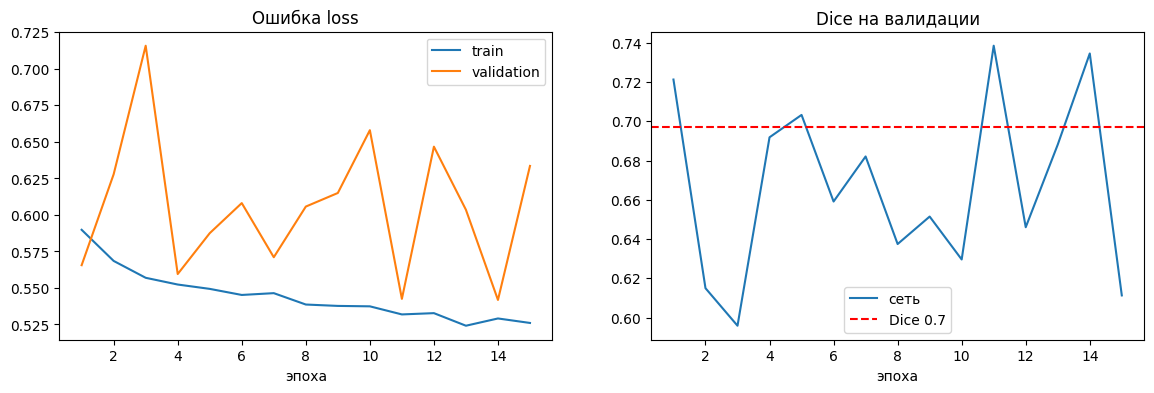

In [29]:
hist = pd.DataFrame(history)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(hist["epoch"], hist["train_loss"], label="train")
axes[0].plot(hist["epoch"], hist["val_loss"], label="validation")
axes[0].set_title("Ошибка loss"); axes[0].set_xlabel("эпоха"); axes[0].legend()

axes[1].plot(hist["epoch"], hist["val_dice"], label="сеть")
axes[1].axhline(0.697, color="red", linestyle="--", label="Dice 0.7")
axes[1].set_title("Dice на валидации"); axes[1].set_xlabel("эпоха"); axes[1].legend()
plt.show()

Простая сверточная сеть, обученная с нуля, достигла лучшего Dice 0.739 на 11 эпохе, это лишь немного выше модели-заглушки (0.70). Ошибка на обучении снижается медленно, а результат на валидации нестабилен, то есть сеть недоучилась.

## make_resnet
Беру готовую сеть ResNet34, которая обучена на 1.2 млн фотографий и заменяю ее последний слой на свой с 4 ответами по типам облаков. Сеть уже умеет находить края и текстуры, поэтому ей нужно только подстроиться под облака.

Ранее было 1000 классов ImageNet, теперь 4

In [30]:
def make_resnet():
    m = models.resnet34(weights=models.ResNet34_Weights.IMAGENET1K_V1)
    m.fc = nn.Sequential(
        nn.Dropout(0.3),
        nn.Linear(m.fc.in_features, 4),
    )
    return m

model = make_resnet().to(device)
n_params = sum(p.numel() for p in model.parameters())
print(f"Параметров: {n_params:,}")

Downloading: "https://download.pytorch.org/models/resnet34-b627a593.pth" to /root/.cache/torch/hub/checkpoints/resnet34-b627a593.pth


100%|██████████| 83.3M/83.3M [00:00<00:00, 186MB/s]


Параметров: 21,286,724


## fit
Функция обучения - тот же цикл, что для простой сети, но скорость обучения постепенно уменьшается от эпохи к эпохе. Так в начале сеть учится быстро, а в конце уточняет результат.


In [31]:
def fit(model, epochs, lr, save_path):
    loss_fn = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)

    history, best_dice = [], 0
    for epoch in range(1, epochs + 1):
        t0 = time.time()
        tr_loss = train_one_epoch(model, train_dl, optimizer, loss_fn)
        va_loss, dice, _, _ = evaluate(model, val_dl, loss_fn)
        scheduler.step()
        mean_dice = dice.mean().item()
        history.append({"epoch": epoch, "train_loss": tr_loss,
                        "val_loss": va_loss, "val_dice": mean_dice})
        mark = ""
        if mean_dice > best_dice:
            best_dice = mean_dice
            torch.save(model.state_dict(), save_path)
            mark = "лучшая"
        print(f"Эпоха {epoch:2d}, train loss {tr_loss:.4f}, val loss {va_loss:.4f} "
              f",val Dice {mean_dice:.4f} | {time.time()-t0:.0f}")
    return pd.DataFrame(history)

## Запуск
Дообучаю ResNet34 10 эпох с маленькой скоростью обучения. Лучшую версию по Dice сохраняю.

In [32]:
set_seed(42)
model = make_resnet().to(device)
hist_resnet = fit(model, epochs=10, lr=3e-4, save_path="resnet34_best.pt")

Эпоха  1, train loss 0.5732, val loss 0.5519 ,val Dice 0.7183 | 85
Эпоха  2, train loss 0.5324, val loss 0.5341 ,val Dice 0.7541 | 84
Эпоха  3, train loss 0.5262, val loss 0.5526 ,val Dice 0.6987 | 84
Эпоха  4, train loss 0.5158, val loss 0.5169 ,val Dice 0.7499 | 84
Эпоха  5, train loss 0.5002, val loss 0.5349 ,val Dice 0.7384 | 85
Эпоха  6, train loss 0.4843, val loss 0.5122 ,val Dice 0.7465 | 84
Эпоха  7, train loss 0.4697, val loss 0.5128 ,val Dice 0.7551 | 84
Эпоха  8, train loss 0.4509, val loss 0.5080 ,val Dice 0.7489 | 84
Эпоха  9, train loss 0.4249, val loss 0.5086 ,val Dice 0.7552 | 85
Эпоха 10, train loss 0.4092, val loss 0.5096 ,val Dice 0.7603 | 84


Предобученная ResNet34 достигла лучшего Dice 0.760 на 10 эпохе, это лучше простой сети (0.739) и модели-заглушки (0.70). Ошибка на обучении снижается до самого конца (0.57 -> 0.41), а на валидации с 6 эпохи почти не меняется (около 0.51). Разрыв между ними растет, это первые признаки переобучения, поэтому обучать дольше 10 эпох не стоит.

## Оценка качества

Dice по каждому классу. Загружаю лучшую версию ResNet34 и считаю Dice отдельно для каждого типа облаков, чтобы понять, какие из них сеть распознает лучше.

In [33]:
model = make_resnet().to(device)
model.load_state_dict(torch.load("resnet34_best.pt"))

loss_fn = nn.BCEWithLogitsLoss()
va_loss, dice, probs, true = evaluate(model, val_dl, loss_fn)

base = dice_score(torch.ones_like(true), true)
res = pd.DataFrame({
    "Заглушка": base.numpy(),
    "ResNet34": dice.numpy(),
}, index=CLASSES)
res["Прирост"] = res["ResNet34"] - res["Заглушка"]
res.loc["Среднее"] = res.mean()
res.round(3)

,Заглушка,ResNet34,Прирост
Sugar,0.812,0.828,0.015
Gravel,0.701,0.714,0.013
Fish,0.681,0.719,0.038
Flower,0.594,0.781,0.187
Среднее,0.697,0.760,0.063


Сеть дает большой прирост только для Flower (+0.187). Для Sugar, Gravel и Fish прирост небольшой (от +0.01 до +0.04) - это мелкие и похожие друг на друга узоры, которые часто встречаются вместе, поэтому их трудно различать.

Проверяю, как часто сеть отвечает "есть" по каждому типу облаков и сравниваю с тем, как часто они встречаются на самом деле.

In [34]:
pred = (probs > 0.5).float()

check = pd.DataFrame({
    "Есть на самом деле, %": true.mean(dim=0).numpy() * 100,
    "Сеть говорит 'есть', %": pred.mean(dim=0).numpy() * 100,
}, index=CLASSES).round(1)
check

,"Есть на самом деле, %","Сеть говорит 'есть', %"
Sugar,68.400002,68.599998
Gravel,54.000000,45.200001
Fish,51.599998,44.900002
Flower,42.299999,39.500000


Сеть отвечает "есть" примерно так же часто, как облака встречаются на самом деле, различает снимки. Для Sugar доля почти точная (68.6% против 68.4%), а Gravel и Fish сеть называет реже.

Подбираю для каждого типа облаков свой порог "есть/нет" вместо 0.5. Пороги подбираю на одной половине валидационных снимков, а проверяю на другой, чтобы результат был честным.
1. argmax - номер лучшего

In [35]:
half = len(probs) // 2
p_tune, y_tune = probs[:half], true[:half]
p_test, y_test = probs[half:], true[half:]

thresholds = np.arange(0.10, 0.91, 0.05)
best_thr = []
for i in range(4):
    scores = [dice_score((p_tune[:, i] > t).float(), y_tune[:, i]).item() for t in thresholds]
    best_thr.append(thresholds[int(np.argmax(scores))])
best_thr = torch.tensor(best_thr, dtype=torch.float32)

d05   = dice_score((p_test > 0.5).float(), y_test)
dbest = dice_score((p_test > best_thr).float(), y_test)

table = pd.DataFrame({
    "Подобранный порог": best_thr.numpy(),
    "Dice при 0.5": d05.numpy(),
    "Dice с подобранным порогом": dbest.numpy(),
}, index=CLASSES)
table.loc["Среднее"] = table.mean()
table.round(3)

,Подобранный порог,Dice при 0.5,Dice с подобранным порогом
Sugar,0.40,0.817,0.819
Gravel,0.25,0.721,0.747
Fish,0.25,0.722,0.736
Flower,0.30,0.761,0.792
Среднее,0.30,0.755,0.773


Подбор своего порога для каждого типа облаков повысил средний Dice с 0.755 до 0.773, больше всего Flower и Gravel. Все лучшие пороги оказались ниже 0.5 (от 0.25 до 0.40).

Смотрю на снимки, где сеть увереннее всего отвечает "есть" где она права и где ошибается. Для ошибок вывожу, какие облака там были на самом деле, чтобы понять, какие узоры сеть путает.
1. p = probs[:, i].numpy() - вероятности сети для класса
2. y = true[:, i].numpy() - правильные ответы 0/1
3. order = np.argsort(-p) - номера снимков от самой высокой вероятности к самой низкой

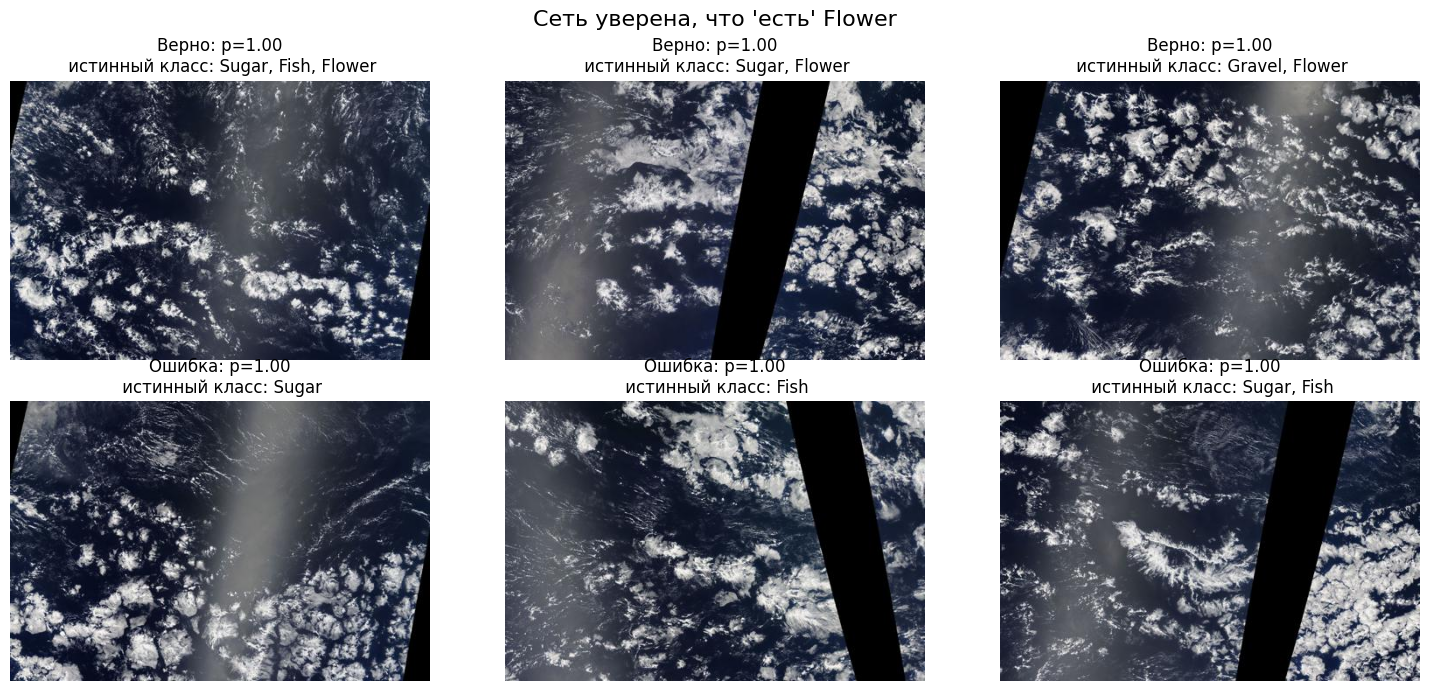

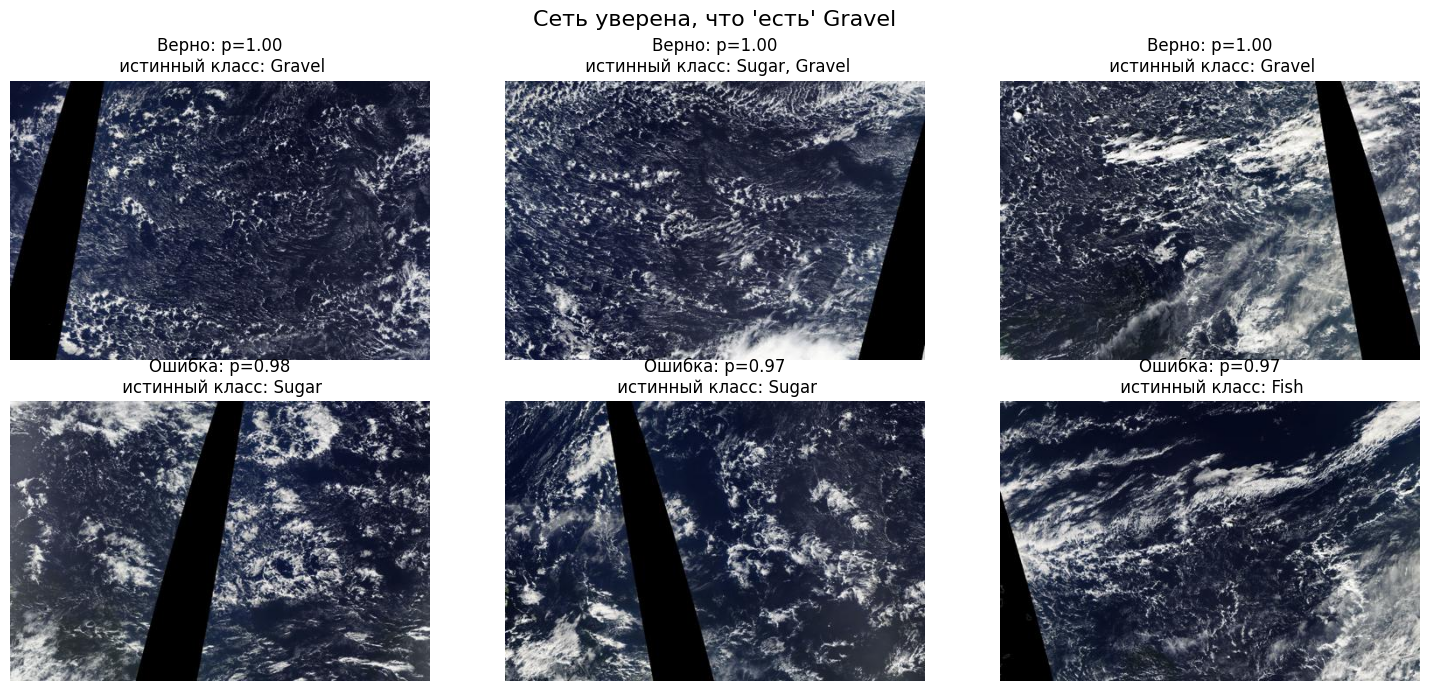

In [36]:
def show_examples(cls, n=3):
    i = CLASSES.index(cls)
    p = probs[:, i].numpy()
    y = true[:, i].numpy()
    order = np.argsort(-p)

    correct     = [k for k in order if y[k] == 1][:n]
    false_alarm = [k for k in order if y[k] == 0][:n]

    fig, axes = plt.subplots(2, n, figsize=(5 * n, 7))
    for row, idxs, title in [(0, correct, "Верно"), (1, false_alarm, "Ошибка")]:
        for ax, k in zip(axes[row], idxs):
            ax.imshow(Image.open(f"data/train_small/{val_names[k]}"))
            actual = [CLASSES[j] for j in range(4) if true[k, j] == 1]
            ax.set_title(f"{title}: p={p[k]:.2f}\n истинный класс: {', '.join(actual)}")
            ax.axis("off")
    plt.suptitle(f"Сеть уверена, что 'есть' {cls}", fontsize=16)
    plt.tight_layout()
    plt.show()

show_examples("Flower")
show_examples("Gravel")

Сеть чаще всего путает Gravel с Sugar, реже с Fish.

# Итоги

**Задача:** по спутниковому снимку определить, какие из 4 типов облаков (Sugar, Gravel, Fish, Flower) на нем есть. Качество оцениваю по Dice.

**Данные:** 5 546 снимков, 80% на обучение, 20% на проверку. На 76% снимков есть два и больше типа облаков, поэтому сеть отвечает "есть/нет" отдельно по каждому типу.

**Результаты:**

Модель-Dice:

1. Заглушка "всегда есть" - 0.697
2. Простая сверточная сеть (с нуля) - 0.739
3. ResNet34 (предобученная) - 0.760
4. ResNet34 + подобранные пороги -  0.773

**Что узнала об облаках:**
- Flower распознается лучше всего;
- Sugar, Gravel и Fish - похожие друг на друга узоры, которые часто встречаются вместе. Сеть их путает, особенно Gravel с Sugar;
- Flower и Gravel редко встречаются на одном снимке;
- Часть ошибок может объясняться неточной разметкой.

**Что можно улучшить:**
1. обучать на снимках большего размера;
2. использовать больше аугментаций или более мощную сеть;
3. объединить ответы нескольких сетей.